In [1]:
%pip install -q ultralytics==8.4.177
!git clone https://github.com/mdmohsin212/WasteScope.git

fatal: destination path 'WasteScope' already exists and is not an empty directory.


In [2]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import sys
from pathlib import Path

REPO_DIR = Path("/content/WasteScope")
sys.path.insert(0, str(REPO_DIR))

In [ ]:
import hashlib
import json
import shutil
import zipfile
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO
from ultralytics.data.utils import IMG_FORMATS

from src.data.annotations import read_yolo_labels
from src.data.boxes import xyxy_to_xywhn, xyxy_to_coco_xywh, xywhn_to_xyxy
from src.data.splits import SplitManifest, video_id
from src.evaluation.metrics import coco_results, detection_errors, evaluate_coco

In [6]:
REPO_DIR = Path("/content/wastescope-urban-intelligence")
sys.path.insert(0, str(REPO_DIR))
BASE = Path("/content/drive/MyDrive/WasteScope")
RUN_NAME = "D0_yolo26n_640"

DRIVE_RUN = BASE / "runs" / "detect" / RUN_NAME
VAL_ZIP = BASE / "prepared" / "detection" / "val_v2.zip"
MANIFEST_PATH = BASE / "manifests" / "video_split.json"
DRIVE_REPORT = BASE / "reports" / "detection" / RUN_NAME / "val"

WORK = Path("/content/wastescope_analysis") / RUN_NAME
LOCAL_RUN = WORK / "training_run"
DATA = Path("/content/detection")
OUT = WORK / "validation"

REVIEW_CONF = 0.25
N_EXAMPLES = 4
OUT.mkdir(parents=True, exist_ok=True)

In [7]:
for relative in ("args.yaml", "results.csv", "weights/best.pt"):
    destination = LOCAL_RUN / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(DRIVE_RUN / relative, destination)

shutil.copy2(MANIFEST_PATH, WORK / "video_split.json")
manifest = SplitManifest.from_file(WORK / "video_split.json")
names = list(manifest.classes)

ready = DATA / "val.ready"
if not ready.exists():
    DATA.mkdir(parents=True, exist_ok=True)
    local_zip = DATA / "val.zip"
    shutil.copy2(VAL_ZIP, local_zip)
    with zipfile.ZipFile(local_zip) as archive:
        archive.extractall(DATA)
    local_zip.unlink()
    ready.write_text("Extracted successfully")

image_paths = sorted(
    p for p in (DATA / "val" / "images").iterdir()
    if p.is_file() and p.suffix.lower().lstrip(".") in IMG_FORMATS
)

In [8]:
(DATA / "data.yaml").write_text(yaml.safe_dump({
    "path": str(DATA), 
    "train": "train/images", 
    "val": "val/images",
    "names": dict(enumerate(names))
}, sort_keys=False))

train_args = yaml.safe_load((LOCAL_RUN / "args.yaml").read_text())
history = pd.read_csv(LOCAL_RUN / "results.csv")
history.columns = history.columns.str.strip()
IMGSZ = int(train_args["imgsz"])
BEST = LOCAL_RUN / "weights" / "best.pt"

print("Run:", RUN_NAME)
print("Validation images:", len(image_paths))
print("Completed epochs:", int(history["epoch"].max()))
print("Evaluation image size:", IMGSZ)
print("Classes:", names)

Run: D0_yolo26n_640
Validation images: 5018
Completed epochs: 75
Evaluation image size: 640
Classes: ['container_yellow', 'container_green', 'container_default', 'container_blue', 'container_oil', 'container_battery', 'container_biodegradable']


**Inspect training history**

In [9]:
metric_columns = {
    "metrics/precision(B)": "Precision", "metrics/recall(B)": "Recall",
    "metrics/mAP50(B)": "mAP50", "metrics/mAP50-95(B)": "mAP50-95",
}
best_logged = history.loc[history["metrics/mAP50-95(B)"].idxmax()]

display(best_logged[["epoch", *metric_columns]].rename(
    index={"epoch": "Epoch", **metric_columns}
).to_frame("Best logged validation epoch").round(4))

,Best logged validation epoch
Epoch,55.0000
Precision,0.8868
Recall,0.7976
mAP50,0.8535
mAP50-95,0.6415


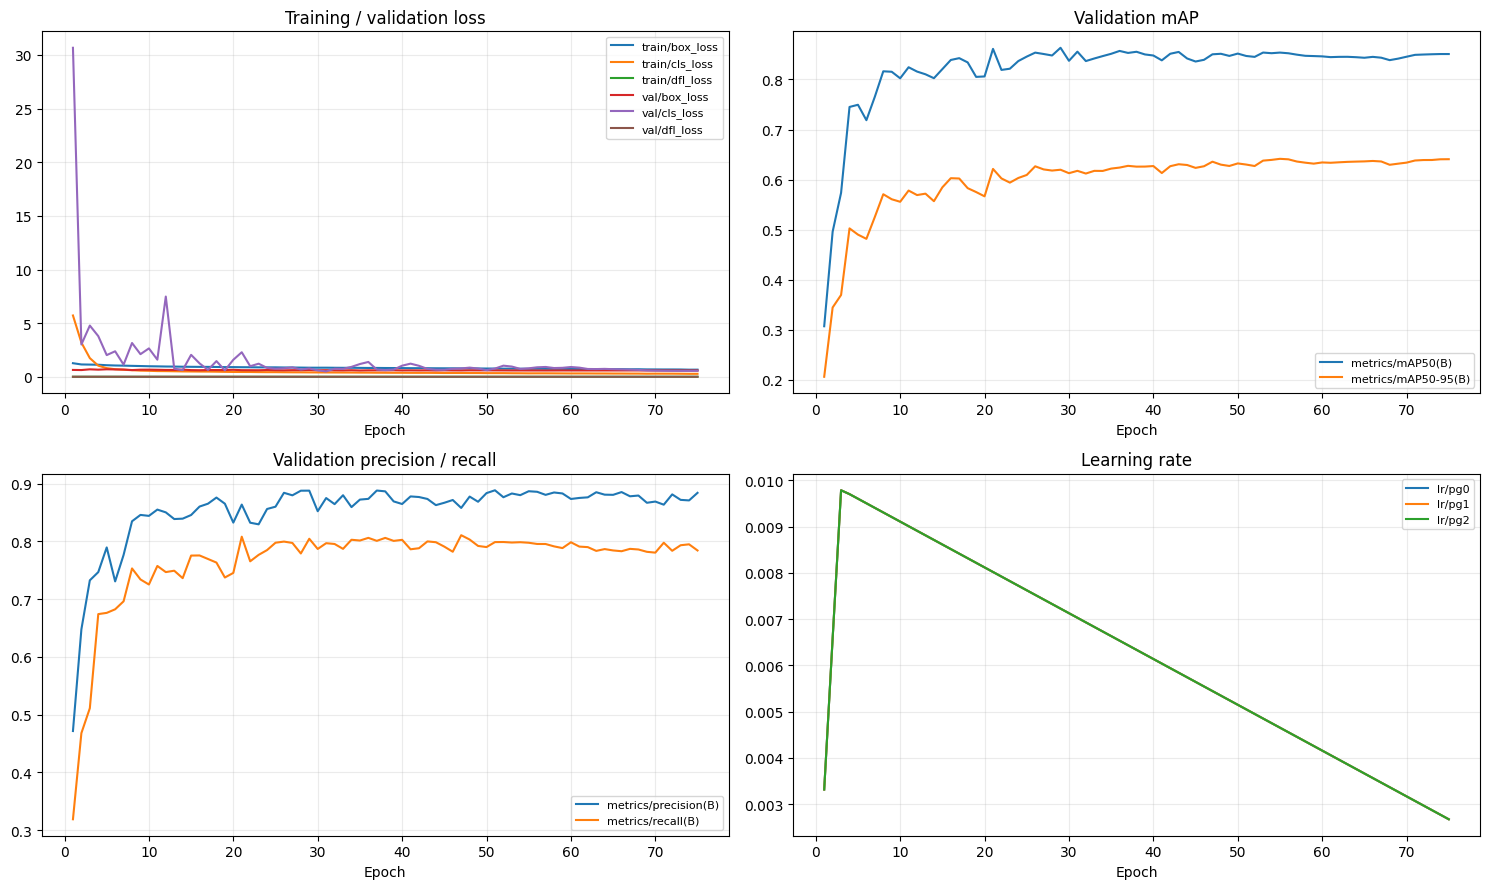

In [10]:
groups = [
    ([c for c in history if c.endswith("_loss")], "Training / validation loss"),
    (["metrics/mAP50(B)", "metrics/mAP50-95(B)"], "Validation mAP"),
    (["metrics/precision(B)", "metrics/recall(B)"], "Validation precision / recall"),
    ([c for c in history if c.startswith("lr/")], "Learning rate")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, (columns, title) in zip(axes.flat, groups):
    for column in columns:
        ax.plot(history["epoch"], history[column], label=column)
    ax.set(title=title, xlabel="Epoch")
    ax.grid(alpha=0.25)
    if columns:
        ax.legend(fontsize=8)
        
fig.tight_layout()
fig.savefig(OUT / "training_curves.png", dpi=160)
plt.show()
plt.close(fig)

**Validate the best checkpoint once**

In [11]:
model = YOLO(str(BEST))
gpu_available = torch.cuda.is_available()
validation = {}

def capture_predictions(validator):
    validation.update(
        predictions=validator.jdict, seen=validator.seen,
        precision=validator.args.quantize
    )

model.add_callback("on_val_end", capture_predictions)

val_metrics = model.val(
    data=str(DATA / "data.yaml"), 
    split="val", 
    imgsz=IMGSZ,
    batch=16,
    device=0,
    workers=2,
    quantize=16,
    conf=0.001, 
    iou=0.7, 
    max_det=300,
    nms=train_args.get("nms"), 
    agnostic_nms=False,
    augment=False, 
    rect=True, 
    cache=False,
    plots=True, 
    save_json=True,
    project=str(WORK), 
    name=OUT.name, 
    exist_ok=True
)

overall = pd.DataFrame([{
    "Run": RUN_NAME, 
    "Split": "val",
    "Precision": val_metrics.box.mp, 
    "Recall": val_metrics.box.mr,
    "mAP50": val_metrics.box.map50, 
    "mAP50-95": val_metrics.box.map
}]).set_index("Run")

display(overall.round(4))

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,376,201 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 411.0±563.1 MB/s, size: 2129.3 KB)
val: Scanning /content/detection/val/labels... 5018 images, 2529 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5018/5018 96.6it/s 52.0s<0.0s
val: New cache created: /content/detection/val/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 314/314 1.3it/s 4:040.3ss
                   all       5018      10203      0.887      0.797      0.838      0.614
      container_yellow       1351       1351      0.729      0.829      0.747      0.535
       container_green       1478       1478      0.893      0.859      0.891      0.644
     container_default       2294       4850      0.949      0.771      0.863      0.619
        container_blue       1606       1606      0.898      

,Split,Precision,Recall,mAP50,mAP50-95
Run,,,,,
D0_yolo26n_640,val,0.8869,0.7972,0.8382,0.6143
